In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [2]:
def fetch_column_labels():
    return [
        'id', 'diagnosis',
        'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
        'smoothness_mean', 'compactness_mean', 'concavity_mean',
        'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
        'radius_se', 'texture_se', 'perimeter_se', 'area_se',
        'smoothness_se', 'compactness_se', 'concavity_se',
        'concave_points_se', 'symmetry_se', 'fractal_dimension_se',
        'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst',
        'smoothness_worst', 'compactness_worst', 'concavity_worst',
        'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst'
    ]

In [3]:
dataset = pd.read_csv('data.csv', header=None, names=fetch_column_labels())

In [4]:
dataset.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [5]:
dataset.shape

(569, 32)

In [6]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [7]:
dataset.isna().sum()

id                         0
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave_points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave_points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave_points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

In [8]:
print(dataset['diagnosis'].value_counts())

diagnosis
B    357
M    212
Name: count, dtype: int64


In [9]:
data_cleaned = dataset.drop(columns=['id'])

In [10]:
lbl_enc = LabelEncoder()
data_cleaned['diagnosis'] = lbl_enc.fit_transform(data_cleaned['diagnosis'])

In [11]:
data_cleaned.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [12]:
X_features = data_cleaned.drop('diagnosis', axis=1)
y_target = data_cleaned['diagnosis']

print("Features Shape:", X_features.shape)
print("Target Shape:", y_target.shape[0])

Features Shape: (569, 30)
Target Shape: 569


In [13]:
train_x, test_x, train_y, test_y = train_test_split(X_features, y_target, test_size=0.2, random_state=42)

print("X_train Shape:", train_x.shape)
print("X_test Shape:", test_x.shape)

X_train Shape: (455, 30)
X_test Shape: (114, 30)


In [14]:
std_scaler = StandardScaler()
train_x_scaled = std_scaler.fit_transform(train_x)
test_x_scaled = std_scaler.transform(test_x)

In [15]:
print("X_train_scaled Shape:", train_x_scaled.shape)
print("X_test_scaled Shape:", test_x_scaled.shape)

X_train_scaled Shape: (455, 30)
X_test_scaled Shape: (114, 30)


In [16]:
pca = PCA()

In [17]:
train_x_all_pca = pca.fit_transform(train_x_scaled)

In [18]:
expected_exp_variance = pca.explained_variance_ratio_ * 100

print("Explained Variance (%):")
print(expected_exp_variance)

Explained Variance (%):
[4.35027816e+01 1.95000069e+01 9.78151887e+00 6.48640944e+00
 5.25337760e+00 4.11279962e+00 2.23559034e+00 1.64795219e+00
 1.38005190e+00 1.20526216e+00 1.05656532e+00 8.83487978e-01
 7.72384348e-01 5.31689053e-01 2.90035907e-01 2.74863963e-01
 2.02120554e-01 1.81312048e-01 1.63703163e-01 1.03921453e-01
 9.98523858e-02 8.78835623e-02 8.09819261e-02 5.76666950e-02
 4.96295906e-02 2.76290404e-02 2.25813282e-02 5.07660981e-03
 2.45885848e-03 4.05623540e-04]


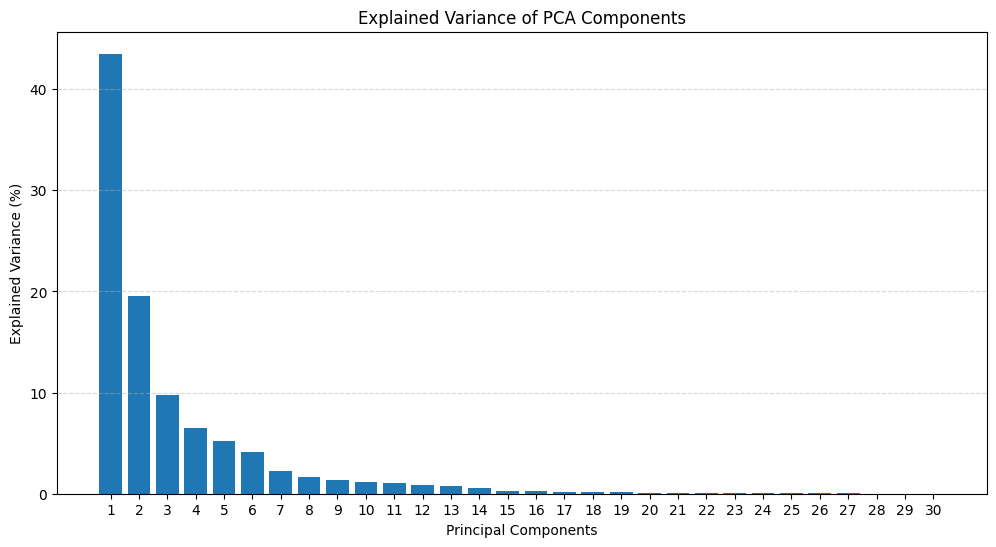

In [19]:
plt.figure(figsize=(12, 6))
plt.bar(range(1, len(expected_exp_variance) + 1), expected_exp_variance)
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("Explained Variance of PCA Components")
plt.xticks(range(1, len(expected_exp_variance) + 1))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [20]:
n_components = 5
pca_model = PCA(n_components=n_components)

In [21]:
train_x_pca = pca_model.fit_transform(train_x_scaled)
test_x_pca = pca_model.transform(test_x_scaled)

In [22]:
print("Original number of features:", train_x_scaled.shape[1])
print("Selected number of components:", n_components)
print("Reduced training data shape:", train_x_pca.shape)
print("Reduced testing data shape:", test_x_pca.shape)

Original number of features: 30
Selected number of components: 5
Reduced training data shape: (455, 5)
Reduced testing data shape: (114, 5)


In [23]:
classifier_original = LogisticRegression(max_iter=10000)
classifier_original.fit(train_x_scaled, train_y)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,10000
,multi_class,'deprecated'


In [24]:
pred_original = classifier_original.predict(test_x_scaled)
score_original = accuracy_score(test_y, pred_original)

In [25]:
print("Accuracy before PCA:", score_original)

Accuracy before PCA: 0.9736842105263158


In [26]:
classifier_pca = LogisticRegression(max_iter=10000)
classifier_pca.fit(train_x_pca, train_y)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,10000
,multi_class,'deprecated'


In [27]:
pred_pca = classifier_pca.predict(test_x_pca)
score_pca = accuracy_score(test_y, pred_pca)

In [28]:
print("Accuracy after PCA:", score_pca)

Accuracy after PCA: 0.9824561403508771


In [29]:
print("Features before PCA:", train_x.shape[1])
print("Features after PCA:", train_x_pca.shape[1])

print("Accuracy before PCA:", score_original * 100, "%")
print("Accuracy after PCA:", score_pca * 100, "%")

Features before PCA: 30
Features after PCA: 5
Accuracy before PCA: 97.36842105263158 %
Accuracy after PCA: 98.24561403508771 %


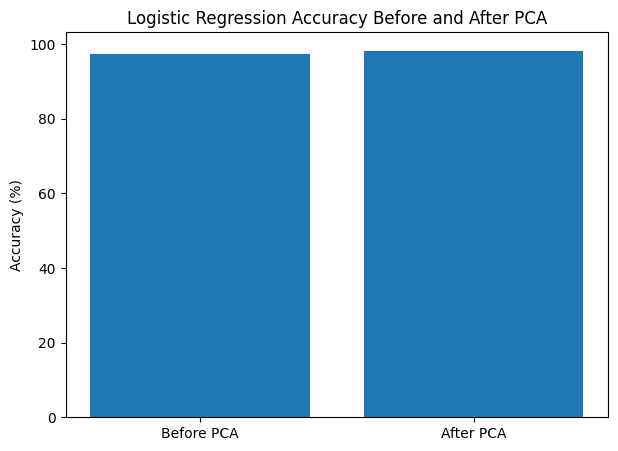

In [30]:
plt.figure(figsize=(7, 5))
plt.bar(["Before PCA", "After PCA"], [score_original * 100, score_pca * 100])
plt.ylabel("Accuracy (%)")
plt.title("Logistic Regression Accuracy Before and After PCA")
plt.show()